In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from matplotlib import pyplot as plt
%matplotlib inline

# Fijar semilla para reproducibilidad
torch.manual_seed(42)
np.random.seed(42)

# Configurar GPU si está disponible, caso contrario CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

Usando dispositivo: cpu


In [2]:
# 1. Apertura del dataset
ruta = '/content/energy_dataset.csv'
df = pd.read_csv(ruta)
print("Dimensiones originales:", df.shape)

# 2. Preprocesamiento numérico (mismo criterio que en tu Lab 2 original)
df_numeric = df.select_dtypes(include=[np.number])
df_numeric = df_numeric.fillna(df_numeric.mean())
df_numeric = df_numeric.fillna(0)

# 3. Separar características (X) y variable objetivo (y)
y_all = df_numeric['price actual'].values.reshape(-1, 1)
X_df = df_numeric.drop(['price actual'], axis=1)
X_all = X_df.values

m, n = X_all.shape
print(f"Total de ejemplos (m): {m}")
print(f"Total de características (n): {n}")

# 4. División en Entrenamiento (80%) y Validación (20%)
indices = np.random.permutation(m)
train_size = int(0.8 * m)

train_idx, val_idx = indices[:train_size], indices[train_size:]
X_train_raw, y_train = X_all[train_idx], y_all[train_idx]
X_val_raw, y_val = X_all[val_idx], y_all[val_idx]

# 5. Normalización Z-score (calculada SOLO sobre train para evitar data leakage)
mu = np.mean(X_train_raw, axis=0)
sigma = np.std(X_train_raw, axis=0)
sigma[sigma == 0] = 1.0  # Evitar división por cero en columnas constantes

X_train = (X_train_raw - mu) / sigma
X_val = (X_val_raw - mu) / sigma

print(f"Set de entrenamiento: {X_train.shape}, Set de validación: {X_val.shape}")

Dimensiones originales: (35064, 29)
Total de ejemplos (m): 35064
Total de características (n): 27
Set de entrenamiento: (28051, 27), Set de validación: (7013, 27)


In [3]:
class EnergyDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = EnergyDataset(X_train, y_train)
val_dataset = EnergyDataset(X_val, y_val)

# Batch size de 256 para aprovechar vectorización en 28,051 ejemplos de entrenamiento
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=1024, shuffle=False)

In [4]:
class RegresionLinealMultiple(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        # Una única capa lineal: y_hat = X * W^T + b
        self.linear = nn.Linear(num_features, 1)

    def forward(self, x):
        return self.linear(x)

model = RegresionLinealMultiple(num_features=n).to(device)
print(model)

RegresionLinealMultiple(
  (linear): Linear(in_features=27, out_features=1, bias=True)
)


In [5]:
# Función de pérdida (Error Cuadrático Medio) y Optimizador
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

epochs = 200
train_loss_history = []
val_loss_history = []
best_val_loss = float('inf')

print("Iniciando entrenamiento en PyTorch...")

for epoch in range(1, epochs + 1):
    # --- Modo Entrenamiento ---
    model.train()
    batch_losses = []
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)

        # 1. Forward pass
        y_pred = model(x_batch)
        loss = criterion(y_pred, y_batch)

        # 2. Backward pass y optimización
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        batch_losses.append(loss.item())

    epoch_train_loss = np.mean(batch_losses)
    train_loss_history.append(epoch_train_loss)

    # --- Modo Evaluación (Validación) ---
    model.eval()
    val_losses = []
    with torch.no_grad():
        for x_batch, y_batch in val_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            y_pred = model(x_batch)
            loss = criterion(y_pred, y_batch)
            val_losses.append(loss.item())

    epoch_val_loss = np.mean(val_losses)
    val_loss_history.append(epoch_val_loss)

    # Guardar el mejor modelo (checkpoint)
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), 'mejor_modelo_energia.pt')

    if epoch % 20 == 0 or epoch == 1:
        print(f"Época [{epoch:3d}/{epochs}] | Train MSE: {epoch_train_loss:.4f} | Val MSE: {epoch_val_loss:.4f}")

print(f"\n¡Entrenamiento finalizado! Mejor Val MSE: {best_val_loss:.4f} (equivale a J ≈ {best_val_loss/2:.2f})")

Iniciando entrenamiento en PyTorch...
Época [  1/200] | Train MSE: 875.5173 | Val MSE: 135.1125
Época [ 20/200] | Train MSE: 85.9095 | Val MSE: 89.0902
Época [ 40/200] | Train MSE: 85.9135 | Val MSE: 89.1463
Época [ 60/200] | Train MSE: 86.0242 | Val MSE: 89.0044
Época [ 80/200] | Train MSE: 86.0619 | Val MSE: 89.1072
Época [100/200] | Train MSE: 85.9281 | Val MSE: 89.0852
Época [120/200] | Train MSE: 85.9004 | Val MSE: 88.9944
Época [140/200] | Train MSE: 85.9868 | Val MSE: 89.0017
Época [160/200] | Train MSE: 85.8719 | Val MSE: 89.0306
Época [180/200] | Train MSE: 85.8962 | Val MSE: 89.0579
Época [200/200] | Train MSE: 85.8980 | Val MSE: 88.9580

¡Entrenamiento finalizado! Mejor Val MSE: 88.8997 (equivale a J ≈ 44.45)


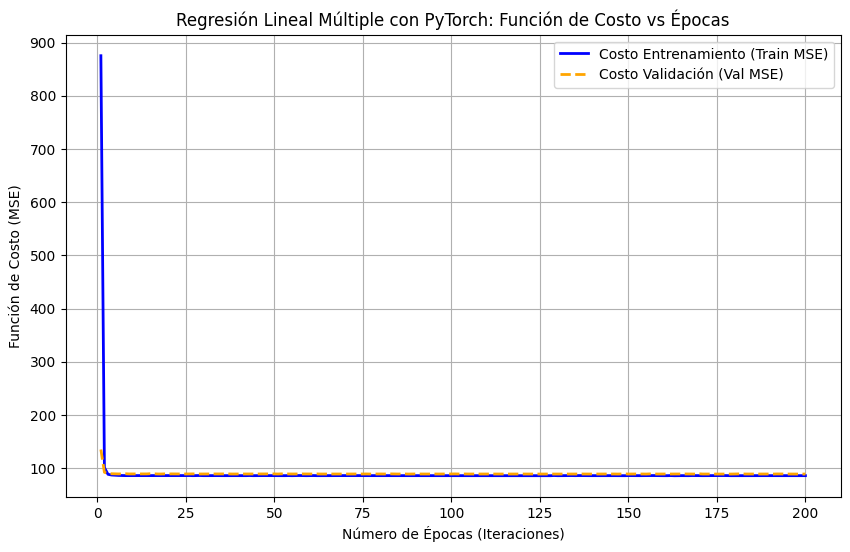

In [6]:
# Cargar los pesos del mejor modelo guardado
model.load_state_dict(torch.load('mejor_modelo_energia.pt'))

plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), train_loss_history, label='Costo Entrenamiento (Train MSE)', lw=2, color='blue')
plt.plot(range(1, epochs + 1), val_loss_history, label='Costo Validación (Val MSE)', lw=2, color='orange', linestyle='--')
plt.xlabel('Número de Épocas (Iteraciones)')
plt.ylabel('Función de Costo (MSE)')
plt.title('Regresión Lineal Múltiple con PyTorch: Función de Costo vs Épocas')
plt.legend()
plt.grid(True)
plt.show()

In [7]:
model.eval()

# Tomamos la primera fila del dataset original (mismo ejemplo de prueba que en tu Lab 2)
X_ejemplo = X_all[0].copy()
X_ejemplo_norm = (X_ejemplo - mu) / sigma

# Convertir a tensor con dimensión (1, 27) y enviar al dispositivo
tensor_ejemplo = torch.tensor(X_ejemplo_norm, dtype=torch.float32).unsqueeze(0).to(device)

with torch.no_grad():
    precio_predicho_pytorch = model(tensor_ejemplo).item()

print(f"Precio predicho (PyTorch): {precio_predicho_pytorch:.2f}")
print(f"Precio real en el dataset: {y_all[0][0]:.2f}")

Precio predicho (PyTorch): 57.88
Precio real en el dataset: 65.41
